In [1]:

#Basic numerical and plotting tools
import math
import time
import glob

import numpy as np
import matplotlib.pyplot as plt

#Symbolic mathematics
import sympy
from sympy import re, im, I, E, symbols, exp

#Scientific computing
from scipy.optimize import minimize
from scipy.special import pro_ang1, legendre, chebyt, chebyu

#Machine learning tools
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import cohen_kappa_score, f1_score

#Deep learning
import tensorflow as tf
from tensorflow.keras.layers import (
    Dense, Flatten, Cropping1D, Concatenate, MaxPooling1D,
    Dropout, Reshape, Conv1D, BatchNormalization, Activation,
    AveragePooling1D, GlobalAveragePooling1D, Lambda, Input,
    Add, UpSampling1D, Multiply
)
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras import losses, backend as K
from tensorflow.keras.losses import (
    Hinge, binary_crossentropy, categorical_crossentropy
)
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, TensorBoard,
    ReduceLROnPlateau, LearningRateScheduler, Callback
)
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.optimizers import Adam, RMSprop, SGD


In [2]:
#Experiment parameters
Nsamples = np.logspace(1, np.log10(10000), 10).astype(int)
Ntest = 1000

Para_slep = [10]
total_runs = 20

In [3]:
#Generate random sample points uniformly on [-1, 1]
rng = np.random.default_rng(42)

def generate_samples(n_samples):
    if isinstance(n_samples, (list, np.ndarray)):
        n_samples = n_samples[0]

    n_samples = int(n_samples)
    return rng.uniform(-1, 1, n_samples)

In [4]:
#Define the target function g(x) = exp(-x^2 / 2)
def target_function(x):
    return np.exp(-0.5 * x**2)

In [5]:
#Evaluate the normalized Chebyshev polynomial of the first kind
def normalized_chebyshev(x, degree):
    normalization = (
        np.sqrt(np.pi)
        if degree == 0
        else np.sqrt(np.pi / 2)
    )
    return chebyt(degree)(x) / normalization



In [6]:
#Build the matrix for the least-squares approximation

def build_chebyshev_matrix(samples, n_basis):
    A = np.zeros((len(samples), n_basis))

    for j in range(n_basis):
        for k in range(len(samples)):
            A[k, j] = normalized_chebyshev(samples[k], j)

    return A

In [7]:
#Evaluate the normalized Legendre polynomial of degree j

def normalized_legendre(x, degree):
    polynomial = legendre(degree)(x)

    normalization = np.sqrt(2 / (2 * degree + 1))

    return polynomial / normalization


In [8]:
#Build the matrix for the least-squares approximation using normalized Legendre polynomials

def build_legendre_matrix(samples, n_basis):
    A = np.zeros((len(samples), n_basis))

    for j in range(n_basis):
        for k in range(len(samples)):
            A[k, j] = normalized_legendre(samples[k], j)

    return A

In [9]:
#Calculate the normalization quantity for a Slepian function

def slepian_normalization(degree, bandwidth):
    alpha = 0
    theta = np.linspace(-1, 1, 200)

    pswf_values = pro_ang1(alpha, degree, bandwidth, theta)
    pswf_values = pswf_values[0]

    pswf_values = pswf_values[1:199]
    # normalization = np.linalg.norm(pswf_values) / np.sqrt(len(theta) - 1)
    ##check on the normalization method##
    normalization = np.sqrt(0.5 * np.trapezoid(np.abs(pswf_values)**2, x=theta[1:-1]))

    return normalization


slepian_norms = np.zeros(Para_slep[-1])

for degree in range(Para_slep[-1]):
    slepian_norms[degree] = slepian_normalization(degree, 4)


In [10]:
#Evaluate the normalized Slepian function of degree j and bandwidth c

def normalized_slepian(x, degree, bandwidth):
    alpha = 0

    pswf_values = pro_ang1(alpha, degree, bandwidth, x)
    pswf_values = pswf_values[0]

    normalization = slepian_norms[degree]

    return pswf_values / normalization


In [11]:
#Build the matrix for the least-squares approximation using normalized Slepian functions

def build_slepian_matrix(samples, n_basis):
    A = np.zeros((len(samples), n_basis))

    for j in range(n_basis):
        for k in range(len(samples)):
            A[k, j] = normalized_slepian(samples[k], j, 4)

    return A


In [12]:

#Initialize the error arrays
MSE_cheby = np.zeros((len(Para_slep), len(Nsamples), total_runs))
MSE_leg = np.zeros((len(Para_slep), len(Nsamples), total_runs))
MSE_slep = np.zeros((len(Para_slep), len(Nsamples), total_runs))

start_time = time.time()
total_iterations = total_runs * len(Para_slep) * len(Nsamples)
counter = 0

#Repeat the experiment with independently generated data
for run in range(total_runs):

    #Generate the largest training sample set
    training_samples_all = generate_samples(Nsamples[-1])
    training_values_all = target_function(training_samples_all)

    #Build the three training matrices
    chebyshev_matrix_all = build_chebyshev_matrix(
        training_samples_all, Para_slep[-1]
    )
    legendre_matrix_all = build_legendre_matrix(
        training_samples_all, Para_slep[-1]
    )
    slepian_matrix_all = build_slepian_matrix(
        training_samples_all, Para_slep[-1]
    )

    #Generate the test set and evaluate the target function
    test_samples = generate_samples(Ntest)
    test_values = target_function(test_samples)

    #Build the three test matrices
    test_chebyshev_matrix_all = np.array([
        [normalized_chebyshev(x, j) for j in range(Para_slep[-1])]
        for x in test_samples
    ])

    test_legendre_matrix_all = np.array([
        [normalized_legendre(x, j) for j in range(Para_slep[-1])]
        for x in test_samples
    ])

    test_slepian_matrix_all = np.array([
        [normalized_slepian(x, j, 4) for j in range(Para_slep[-1])]
        for x in test_samples
    ])

    for order_index in range(len(Para_slep)):

        for sample_index in range(len(Nsamples)):

            # Select the required number of samples and basis functions
            n_samples = Nsamples[sample_index]
            n_basis = Para_slep[order_index]

            chebyshev_matrix = chebyshev_matrix_all[:n_samples, :n_basis]
            legendre_matrix = legendre_matrix_all[:n_samples, :n_basis]
            slepian_matrix = slepian_matrix_all[:n_samples, :n_basis]

            training_values = training_values_all[:n_samples]

            test_chebyshev_matrix = test_chebyshev_matrix_all[:, :n_basis]
            test_legendre_matrix = test_legendre_matrix_all[:, :n_basis]
            test_slepian_matrix = test_slepian_matrix_all[:, :n_basis]

            # Fit and evaluate the Chebyshev approximation
            chebyshev_coefficients = np.linalg.lstsq(
                chebyshev_matrix, training_values, rcond=None
            )[0]

            prediction = test_chebyshev_matrix @ chebyshev_coefficients
            error = np.linalg.norm(prediction - test_values) / np.sqrt(Ntest)
            MSE_cheby[order_index, sample_index, run] = error

            # Fit and evaluate the Legendre approximation
            legendre_coefficients = np.linalg.lstsq(
                legendre_matrix, training_values, rcond=None
            )[0]

            prediction = test_legendre_matrix @ legendre_coefficients
            error = np.linalg.norm(prediction - test_values) / np.sqrt(Ntest)
            MSE_leg[order_index, sample_index, run] = error

            # Fit and evaluate the Slepian approximation
            slepian_coefficients = np.linalg.lstsq(
                slepian_matrix, training_values, rcond=None
            )[0]

            prediction = test_slepian_matrix @ slepian_coefficients
            error = np.linalg.norm(prediction - test_values) / np.sqrt(Ntest)
            MSE_slep[order_index, sample_index, run] = error

            #Update and display progress
            counter += 1
            now_time = time.time()

            progress = 100 * counter / total_iterations
            remaining_time = (
                (total_iterations - counter)
                * (now_time - start_time)
                / counter
            )

            print(
                f"Error: {error}, "
                f"Progress: {progress:.2f}%, "
                f"approx. {remaining_time:.1f} seconds remaining."
            )


Error: 6.432275312920325e-07, Progress: 0.50%, approx. 2558.2 seconds remaining.
Error: 8.082931357707606e-08, Progress: 1.00%, approx. 1272.7 seconds remaining.
Error: 4.055182777852121e-08, Progress: 1.50%, approx. 844.2 seconds remaining.
Error: 2.190987918412285e-08, Progress: 2.00%, approx. 630.0 seconds remaining.
Error: 1.4329474209142421e-08, Progress: 2.50%, approx. 501.5 seconds remaining.
Error: 1.3037639261428062e-08, Progress: 3.00%, approx. 415.7 seconds remaining.
Error: 1.2205379621478189e-08, Progress: 3.50%, approx. 354.5 seconds remaining.
Error: 1.2177750320705914e-08, Progress: 4.00%, approx. 308.6 seconds remaining.
Error: 1.2137444279510519e-08, Progress: 4.50%, approx. 272.9 seconds remaining.
Error: 1.2114790017461922e-08, Progress: 5.00%, approx. 244.4 seconds remaining.
Error: 3.272635806931209e-07, Progress: 5.50%, approx. 442.1 seconds remaining.
Error: 4.20168202223622e-08, Progress: 6.00%, approx. 403.2 seconds remaining.
Error: 1.4540125772782148e-08, Pr

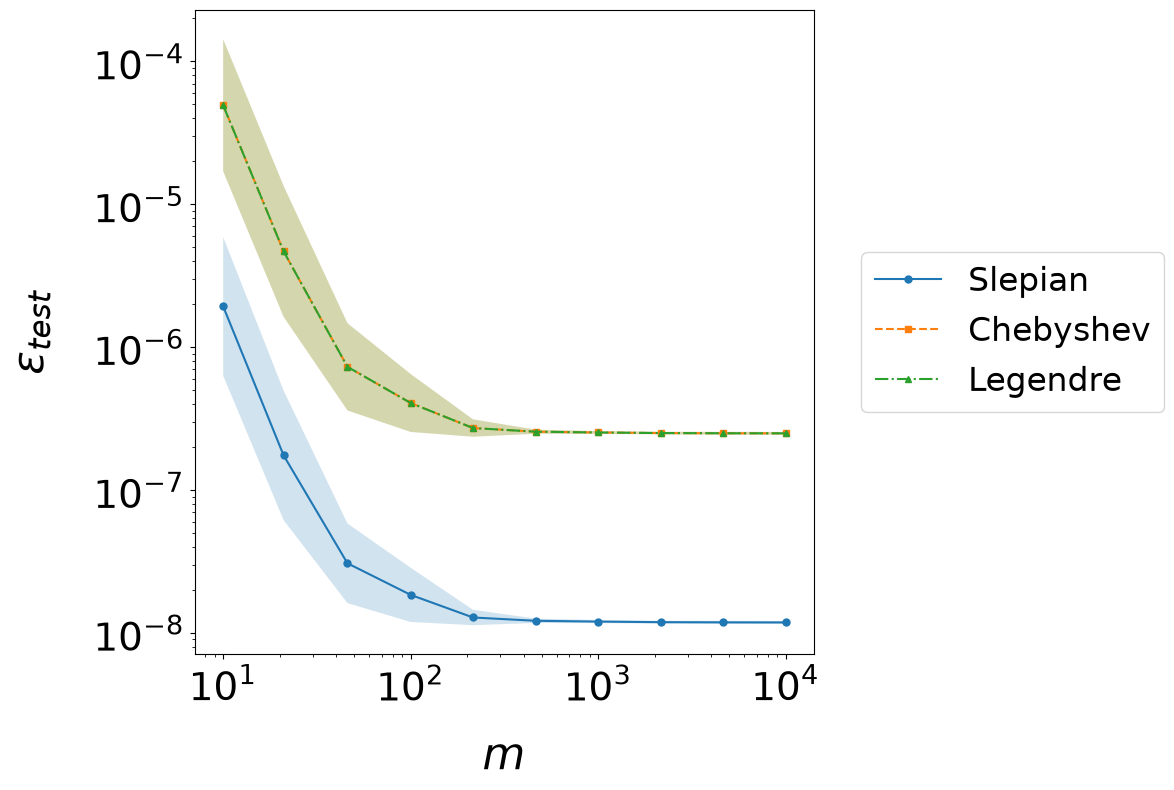

In [13]:
#Plot test error versus training sample size

plt.figure(figsize=(12, 8))

#Mean error across independent runs
results_mean_cheby = np.mean(MSE_cheby, axis=2)
results_mean_leg = np.mean(MSE_leg, axis=2)
results_mean_slep = np.mean(MSE_slep, axis=2)

# Relative standard deviation across independent runs
results_lower_cheby = np.std(MSE_cheby, axis=2) / results_mean_cheby
results_lower_leg = np.std(MSE_leg, axis=2) / results_mean_leg
results_lower_slep = np.std(MSE_slep, axis=2) / results_mean_slep

for i in range(len(Para_slep)):

    #Slepian basis
    plt.loglog(
        Nsamples, results_mean_slep[i, :],
        color='tab:blue', linestyle='-', marker='o',
        markersize=5, label="Slepian"
    )
    plt.fill_between(
        Nsamples,
        results_mean_slep[i, :] / (1 + results_lower_slep[i, :]),
        results_mean_slep[i, :] * (1 + results_lower_slep[i, :]),
        alpha=0.2
    )

    #Chebyshev basis
    plt.loglog(
        Nsamples, results_mean_cheby[i, :],
        color='tab:orange', linestyle='--', marker='s',
        markersize=5, label="Chebyshev"
    )
    plt.fill_between(
        Nsamples,
        results_mean_cheby[i, :] / (1 + results_lower_cheby[i, :]),
        results_mean_cheby[i, :] * (1 + results_lower_cheby[i, :]),
        alpha=0.2
    )

    #Legendre basis
    plt.loglog(
        Nsamples, results_mean_leg[i, :],
        color='tab:green', linestyle='-.', marker='^',
        markersize=5, label="Legendre"
    )
    plt.fill_between(
        Nsamples,
        results_mean_leg[i, :] / (1 + results_lower_leg[i, :]),
        results_mean_leg[i, :] * (1 + results_lower_leg[i, :]),
        alpha=0.2
    )

plt.xlabel(r'$m$', fontsize=32, labelpad=18)
plt.ylabel(r'$\epsilon_{test}$', fontsize=32, labelpad=28)

plt.tick_params(axis='both', which='major', labelsize=28)
plt.tick_params(axis='both', which='minor', labelsize=28)

plt.legend(
    fontsize=24,
    loc='center left',
    bbox_to_anchor=(1.05, 0.5),
    ncol=1
)

plt.tight_layout()
plt.savefig("errorvsm_expo_uni.pdf")
plt.show()
